### **Dimensionality Reduction**

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import umap
import shap
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from ucimlrepo import fetch_ucirepo 
from sklearn.datasets import make_moons, load_digits, load_iris, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

## PCA

PCA (Principal Component Analysis) გარდაქმნის ორიგინალურ მახასიათებლებს ახალ ორთოგონალურ კომპონენტებად - მთავარ კომპონენტებად (principal components), რომლებიც მაქსიმალურ ვარიაციას ინახავენ მონაცემებში. PCA გამოიყენება:

- განზომილების შემცირებისთვის (dimensionality reduction)
- მონაცემების ვიზუალიზაციისთვის, როცა მონაცემებს ბევრი მახასიათებელი აქვს და რთულია მათი აღქმა
- მულტიკოლინეარობისას 

ვთქვათ გვაქვს $n$ მონაცემი და $m$ მახასიათებელი, მაშინ მონაცემების მატრიცას აქვს შემდეგი სახე:

$$
X \in \mathbb{R}^{n \times m}
$$

1. მონაცემების სტანდარტიზაცია
   
   ყოველი მახასიათებლისთვის საშუალო და სტანდარტული გადახრა:
$$
\mu_j = \frac{1}{n}\sum_{i=1}^n X_{ij}
$$

$$
\sigma_j = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (X_{ij} - \mu_j)^2}$$

სტანდარტიზებული მატრიცა (Z):

$$
Z_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j}, \quad i = 1,\dots,n,\ j = 1,\dots,m$$


$$
Z = \text{standardize}(X)$$

---

2. კოვარიაციული მატრიცის აგება

$$C = \frac{1}{n-1} Z^T Z$$

---

3. Eigenvalue / Eigenvector დაშლა

eigendecomposition:

$$
C v_i = \lambda_i v_i$$

* $v_i \in \mathbb{R}^{m}$ - eigenvector (მთავარი კომპონენტის მიმართულება)
* $\lambda_i \in \mathbb{R}$ - eigenvalue (რამდენად დიდ ვარიაციას შეიცავს ეს მიმართულება)

ყველა eigenvector-ს ვაგებთ მატრიცად:

$$V = [v_1 \ v_2 \ \dots \ v_m] \in \mathbb{R}^{m \times m}$$

eigenvalue-ები დიაგონალზე:

$$\Lambda = \text{diag}(\lambda_1, \lambda_2, \dots, \lambda_m)$$

მაშინ:

$$C = V \Lambda V^T,$$ $$V^T V = I$$

---

4. eigenvalue-ების დალაგება
   
$$\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_m$$

ამ თანმიმდევრობის შესაბამისად ვალაგებთ eigenvector-ებსაც:

* $v_1$ შეესაბამება $\lambda_1$-ს
* $v_2$ - $\lambda_2$-ს

---

5. პირველი $k$ კომპონენტის შერჩევა

გვსურს განზომილების შემცირება: $m \to k$, სადაც $k < m$.

ვირჩევთ:

$$
W = [v_1 \ v_2 \ \dots \ v_k] \in \mathbb{R}^{m \times k}$$


---

6. მონაცემების პროექცია ახალი კომპონენტების სივრცეში

ახლა უკვე შეგვიძლია ახალი კომპონენტების გამოთვლა - ანუ თითოეული ობიექტის კოორდინატები PCA-ს სივრცეში:

$$
T = Z W$$

---

შევაჯამოთ:

1. სტანდარტიზაცია:

$$Z_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j}$$

2. კოვარიაციული მატრიცა:

$$C = \frac{1}{n-1} Z^T Z$$

3. Eigenvalue / Eigenvector დაშლა:

$$C v_i = \lambda_i v_i,\quad C = V\Lambda V^T$$

4. პირველი $k$ კომპონენტის შერჩევა:

$$W = [v_1, \dots, v_k]$$

5. მონაცემების ტრანსფორმაცია:

$$T = Z W$$

### მაგალითი

ვთქვათ გვაქვს მონაცემები 2 მახასიათებლით
$$
X = \begin{bmatrix}
2 & 0 \\
0 & 2 \\
3 & 1 \\
1 & 3
\end{bmatrix}
$$

1. მონაცემების ცენტრირება (საშუალო გამოვაკლოთ)
   
$$
\mu_{x_1} = 1.5, \qquad \mu_{x_2} = 1.5
$$

$$
Z =
\begin{bmatrix}
0.5 & -1.5 \\
-1.5 & 0.5 \\
1.5 & -0.5 \\
-0.5 & 1.5
\end{bmatrix}
$$

2. კოვარიაციის მატრიცა:

$$
C =
\begin{bmatrix}
1.6667 & -1.0000 \\
-1.0000 & 1.6667
\end{bmatrix}
$$

3. Eigenvalues და Eigenvectors

ვპოულობთ Eigenvalues:

$$\det(C - \lambda I) = 0$$

ანუ:

$$\begin{vmatrix}
1.6667 - \lambda & -1.0000 \\
-1.0000 & 1.6667 - \lambda
\end{vmatrix}
= 0$$

დეტერმინანტი:

$$(1.6667 - \lambda)^2 - 1 = 0$$

ამოვხსნათ:

$$(1.6667 - \lambda)^2 = 1$$

გვაქვს ორი ფესვი:

$$1.6667 - \lambda = 1 \quad \Rightarrow \quad \lambda_1 = 0.6667$$
$$1.6667 - \lambda = -1 \quad \Rightarrow \quad \lambda_2 = 2.6667$$

Eigenvector-ების გამოთვლა

Eigenvector for λ₂ = 2.6667 (დიდი λ → PC1)

ვწერთ:

$$(C - \lambda_2 I)v = 0$$

$$
\begin{bmatrix}
1.6667 - 2.6667 & -1 \\ 
-1 & 1.6667 - 2.6667
\end{bmatrix} = 
\begin{bmatrix}
-1 & -1 \\
-1 & -1
\end{bmatrix}
$$

ანუ 

$$
\begin{bmatrix}
-1 & -1 \\
-1 & -1
\end{bmatrix}
\begin{bmatrix}
v_1 \\
v_2
\end{bmatrix}=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
$$

ეს ნიშნავს:

$$-1\cdot v_1 - 1\cdot v_2 = 0 \quad \Rightarrow \quad v_1 = -v_2$$

ავარჩიოთ მაგალითად $(v_1 = 1), (v_2 = -1)$:

$$v_1 =
\begin{bmatrix}
1 \\
-1
\end{bmatrix}$$

ნორმალიზაცია:

$$|v_1| = \sqrt{1^2 + (-1)^2} = \sqrt{2}$$

ნორმალიზირებული:

$$ v_1 =
\begin{bmatrix}
\frac{1}{\sqrt{2}} \\
\frac{-1}{\sqrt{2}}
\end{bmatrix}=
\begin{bmatrix}
0.7071 \\
-0.7071
\end{bmatrix}$$

Eigenvector for λ₁ = 0.6667 (პატარა λ → PC2)

ახლა:

$$(C - \lambda_1 I)v = 0$$

$$\begin{bmatrix}
1.6667 - 0.6667 & -1 \\
-1 & 1.6667 - 0.6667
\end{bmatrix}=
\begin{bmatrix}
1 & -1 \\
-1 & 1
\end{bmatrix}$$

ანუ 

$$
\begin{bmatrix}
1 & -1 \\
-1 & 1
\end{bmatrix}
\begin{bmatrix}
v_1 \\
v_2
\end{bmatrix}=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
$$

დავწეროთ განტოლება:

$$1\cdot v_1 - 1\cdot v_2 = 0 \quad \Rightarrow \quad v_1 = v_2$$

ავარჩიოთ $(v_1 = 1, v_2 = 1)$:

$$v_2 =
\begin{bmatrix}
1 \\
1
\end{bmatrix}$$

ნორმალიზაცია:

$$|v_2| = \sqrt{1^2 + 1^2} = \sqrt{2}$$

$$v_2 =
\begin{bmatrix}
\frac{1}{\sqrt{2}} \\
\frac{1}{\sqrt{2}}
\end{bmatrix}=
\begin{bmatrix}
0.7071 \\
0.7071
\end{bmatrix}$$

საბოლოო ფორმა: Eigendecomposition

PCA-ში კოვარიაციის მატრიცა იშლება ასე:

$$C = V \Lambda V^T,$$

მატრიცა $V$ - eigenvector-ები სვეტებად:

$$V =
\begin{bmatrix}
0.7071 & 0.7071 \\
-0.7071 & 0.7071
\end{bmatrix}$$

მატრიცა $\Lambda$ - eigenvalue-ები დიაგონალზე:

$$\Lambda =
\begin{bmatrix}
2.6667 & 0 \\
0 & 0.6667
\end{bmatrix}$$

შევამოწმოთ:

$$C = V \Lambda V^T$$

ეს ზუსტად გვაძლევს საწყის კოვარიაციის მატრიცას.

---

* PCA-ის პირველი კომპონენტი არის ის eigenvector, რომელსაც აქვს უდიდესი eigenvalue.
* მეორე კომპონენტი არის პერპენდიკულარული და აქვს მცირე variance.


Eigenvalues:

$$
\lambda_1 = 2.6667, \qquad \lambda_2 = 0.6667
$$

Eigenvectors (ნორმალიზებული):
$$
v_1 =
\begin{bmatrix}
0.7071 \\
-0.7071
\end{bmatrix},
\qquad
v_2 =
\begin{bmatrix}
0.7071 \\
0.7071
\end{bmatrix}
$$

* ესენი არიან PCA-ს ახალი ღერძები (principal components).
* PC1 უნდა იყოს ის ვექტორი, რომელსაც ყველაზე დიდი eigenvalue აქვს.

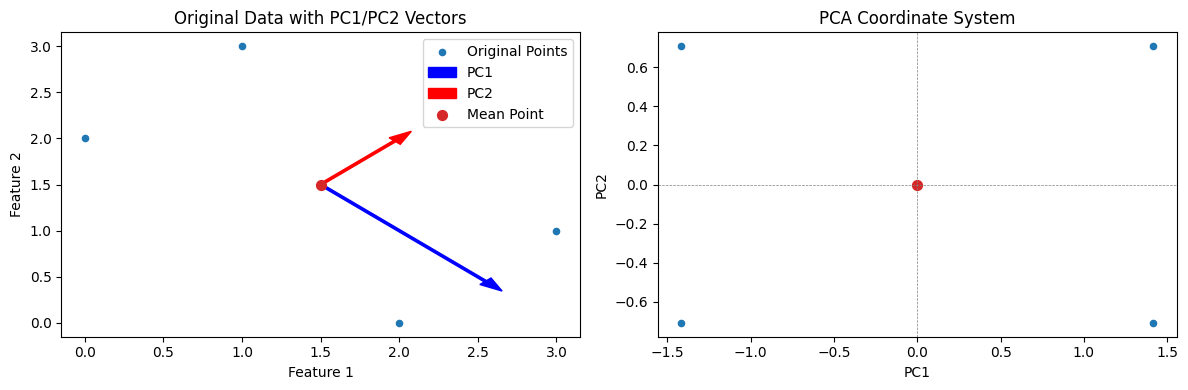

In [3]:
df = pd.DataFrame({"x1": [2,0,3,1], "x2": [0,2,1,3]})
pca = PCA(n_components=2)
pca.fit(df)

mean = df.mean().values
pc1, pc2 = pca.components_

length_pc1 = pca.explained_variance_[0]**0.5
length_pc2 = pca.explained_variance_[1]**0.5

df_pca = pd.DataFrame(pca.transform(df), columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Original data + PC1/PC2 arrows
axes[0].scatter(df["x1"], df["x2"], c="C0", s=20, label="Original Points")
axes[0].arrow(mean[0], mean[1],
              pc1[0] * length_pc1, pc1[1] * length_pc1,
              color="blue", width=0.02, head_width=0.1, length_includes_head=True, label="PC1")
axes[0].arrow(mean[0], mean[1],
              pc2[0] * length_pc2, pc2[1] * length_pc2,
              color="red", width=0.02, head_width=0.1, length_includes_head=True, label="PC2")
axes[0].scatter([mean[0]], [mean[1]], c="C3", s=50, label="Mean Point")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].set_title("Original Data with PC1/PC2 Vectors")
axes[0].legend()

# PCA-transformed data
axes[1].scatter(df_pca["PC1"], df_pca["PC2"], c="C0", s=20)
axes[1].scatter([0], [0], c="C3", marker="o", s=50, label="Mean Point")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.5)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=0.5)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("PCA Coordinate System")

plt.tight_layout()
plt.show()

----

თავდაპირველი სივრცე (features space):

$$
X =
\begin{bmatrix}
\text{feature}_1 \
\text{feature}_2 \
\vdots \
\text{feature}_m
\end{bmatrix}
$$

PCA ქმნის ახალ მახასიათებლებს რომლებიც არიან:
$$
\text{PC}_1, \text{PC}_2, \dots, \text{PC}_m
$$

ძველი მახასიათებლების წონადი კომბინაცია (2 კომპონენტით):

$$
\text{PC}_1 = a_1 \cdot \text{feature}_1 + a_2 \cdot \text{feature}_2 + \dots + a_m \cdot \text{feature}_m
$$
$$
\text{PC}_2 = b_1 \cdot \text{feature}_1 + b_2 \cdot \text{feature}_2 + \dots + b_m \cdot \text{feature}_m
$$

----

In [4]:
# მაგალითი
df = pd.DataFrame({
    "x": [ -3.0, -2.6265223274695537, -2.5696887686062246, -2.5209742895805145,
           -2.374830852503383, -2.2205683355886334, -1.489851150202977, -1.465493910690122,
           -1.4167794316644113, -1.3924221921515563, -1.3924221921515563, -1.2138024357239514,
           -1.1894451962110963, -1.01894451962111, -0.9539918809201624, -0.8484438430311232,
           -0.8484438430311232, -0.8403247631935051, -0.7428958051420844, -0.6617050067659003,
           -0.6211096075778082, -0.6129905277401893, -0.515561569688769, -0.4912043301759139,
           -0.45060893098782184, -0.3125845737483086, -0.28822733423545355, -0.2638700947225985,
           -0.1907983761840324, -0.17456021650879627, 0.00405953991880903, 0.028416779431664096,
            0.036535859269282156, 0.08525033829499318, 0.15020297699594032, 0.16644113667117733,
            0.21515561569688746, 0.23951285520974253, 0.25575101488497953, 0.3125845737483086,
            0.4424898511502029, 0.49120433017591303, 0.5399188092016232, 0.5561569688768602,
            0.5642760487144791, 0.5886332882273342, 0.7672530446549386, 0.9052774018944518,
            1.018944519621109, 1.018944519621109, 1.0433017591339642, 1.2219215155615695,
            1.2381596752368065, 1.2462787550744245, 1.2706359945872796, 1.416779431664411,
            1.52232746955345, 1.5953991880920162, 1.7171853856562924, 1.920162381596752,
            2.074424898511502, 2.2449255751014885, 2.2692828146143436, 2.602165087956698, 3.0],
    "y": [ -1.070707070707071, -3.0, -0.44444444444444464, 0.09090909090909083,
           -1.8181818181818183, -1.5353535353535355, 0.15151515151515138, 0.43434343434343425,
           -0.7575757575757578, -1.1616161616161618, -1.5050505050505052, -0.7272727272727275,
           -0.9393939393939394, 0.404040404040404, -0.4949494949494948, 0.5252525252525251,
            0.1212121212121211, -0.8787878787878789, -1.2525252525252526, 1.4949494949494948,
            0.7272727272727275, 1.1515151515151514, -0.22222222222222232, -0.8181818181818183,
            0.2828282828282829, -0.3939393939393945, -1.0, 0.09090909090909083, 1.4646464646464645,
            0.404040404040404, 0.9797979797979792, 1.2828282828282829, -1.1313131313131315,
           -0.5656565656565657, 0.7676767676767673, 1.7171717171717171, 2.0606060606060606,
           -0.7878787878787881, 0.5151515151515147, -0.3838383838383841, 0.19191919191919204,
            0.9696969696969697, 1.929292929292929, 0.7474747474747474, 1.4646464646464645,
            0.0, 1.404040404040404, 0.8282828282828278, 1.4646464646464645, 2.4343434343434343,
            0.09090909090909083, 1.2020202020202015, 1.8282828282828278, 0.8686868686868685,
            2.8989898989898997, 2.090909090909091, 1.0606060606060606, 0.31313131313131315,
            1.8686868686868685, 2.404040404040405, 1.5555555555555554, 3.0, 2.404040404040405,
            2.575757575757576, 2.8686868686868685]
})

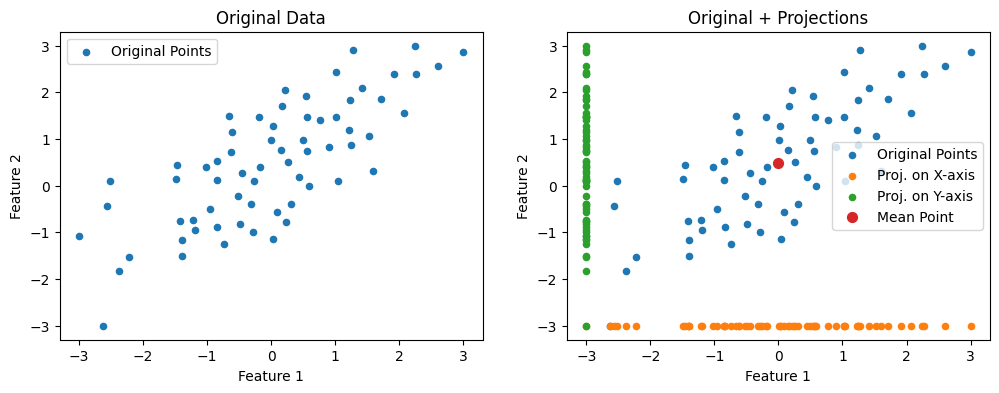

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Original data
ax[0].scatter(df["x"], df["y"], c="C0", s=20, label="Original Points")
ax[0].set_xlabel("Feature 1")
ax[0].set_ylabel("Feature 2")
ax[0].set_title("Original Data")
ax[0].legend()

# Plot 2: Projections on X and Y axes
ax[1].scatter(df["x"], df["y"], c="C0", s=20, label="Original Points")
ax[1].scatter(df["x"], [df["y"].min()] * len(df), c="C1", s=20, label="Proj. on X-axis")
ax[1].scatter([df["x"].min()] * len(df), df["y"], c="C2", s=20, label="Proj. on Y-axis")
ax[1].scatter([df["x"].mean()], [df["y"].mean()], c="C3", s=50, label="Mean Point")
ax[1].set_xlabel("Feature 1")
ax[1].set_ylabel("Feature 2")
ax[1].set_title("Original + Projections")
ax[1].legend();

ავარჩიოთ ის ღერძი, რომელიც საუკეთესოდ ასახავს მონაცემების ვარიაციას, ანუ სადაც მონაცემების დისპერსია ყველაზე მეტად ნარჩუნდება.
ის ღერძი, რომელიც მინიმუმამდე ამცირებს საშუალო კვადრატული შეცდომის (Mean Squared Error, MSE) მნიშვნელობას ორიგინალურ მონაცემებსა და მათ პროექტირებულ წერტილებს შორის. 

<img src="../../images/pca.gif" width="800">

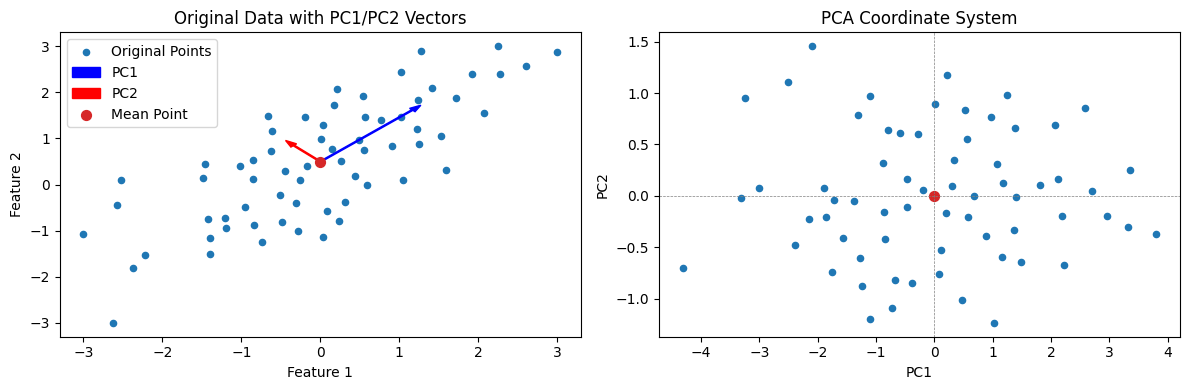

In [6]:
pca = PCA(n_components=2)
pca.fit(df)

mean = df.mean().values
pc1, pc2 = pca.components_

length_pc1 = pca.explained_variance_[0]**0.5
length_pc2 = pca.explained_variance_[1]**0.5

df_pca = pd.DataFrame(pca.transform(df), columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Original data + PC1/PC2 arrows
axes[0].scatter(df["x"], df["y"], c="C0", s=20, label="Original Points")
axes[0].arrow(mean[0], mean[1],
              pc1[0] * length_pc1, pc1[1] * length_pc1,
              color="blue", width=0.02, head_width=0.1, length_includes_head=True, label="PC1")
axes[0].arrow(mean[0], mean[1],
              pc2[0] * length_pc2, pc2[1] * length_pc2,
              color="red", width=0.02, head_width=0.1, length_includes_head=True, label="PC2")
axes[0].scatter([mean[0]], [mean[1]], c="C3", s=50, label="Mean Point")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].set_title("Original Data with PC1/PC2 Vectors")
axes[0].legend()

# PCA-transformed data
axes[1].scatter(df_pca["PC1"], df_pca["PC2"], c="C0", s=20)
axes[1].scatter([0], [0], c="C3", marker="o", s=50, label="Mean Point")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.5)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=0.5)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("PCA Coordinate System")

plt.tight_layout()
plt.show()

ვთქვათ გვაქვს 3 მთავარი კომპონენტი (PC1, PC2, PC3), ისინი არიან:

* ორიგინალური მახასიათებლების წრფივი კომბინაციები
* ორთოგონალურები (მართობულები), ანუ ერთმანეთთან არ კორელირებენ
* თითოეული მაქსიმალურად ხსნის მონაცემთა დისპერსიას
  
| კომპონენტი | მნიშვნელობა                            |
| ---------- | ------------------------------------------- |
| **PC1**    | ხსნის ყველაზე მეტ ვარიაციას |
| **PC2**    | ხსნის შემდეგს, მაგრამ უკვე PC1-ის მიმართ ორთოგონალურია      |
| **PC3**    | ორთოგონალურია პირველ ორთან და ხსნის დარჩენილ დისპერსიას    |

#### Iris Dataset

In [7]:
# მონაცემების ჩატვირთვა
iris = load_iris()
X, y = iris.data, iris.target

In [8]:
# 1. მონაცემების სტანდარტიზაცია
X_scaled = StandardScaler().fit_transform(X)

In [9]:
# 2. კოვარიანციული მატრიცის გამოთვლა
cov_matrix = np.cov(X_scaled.T)

In [10]:
# 3. მნიშვნელობებისა და ვექტორების გამოთვლა
explained_variance, principal_components = np.linalg.eig(cov_matrix)

In [11]:
# 4. დალაგება მნიშვნელობის მიხედვით
sorted_idx = np.argsort(explained_variance)[::-1]
principal_components = principal_components[:, sorted_idx]
explained_variance = explained_variance[sorted_idx]

In [12]:
# 5. მთავარი კომპონენტების არჩევა
k = 2
W = principal_components[:, :k]
X_pca = X_scaled @ W

In [13]:
# ან პირდაპირ sklearn ბიბლიოთეკით
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

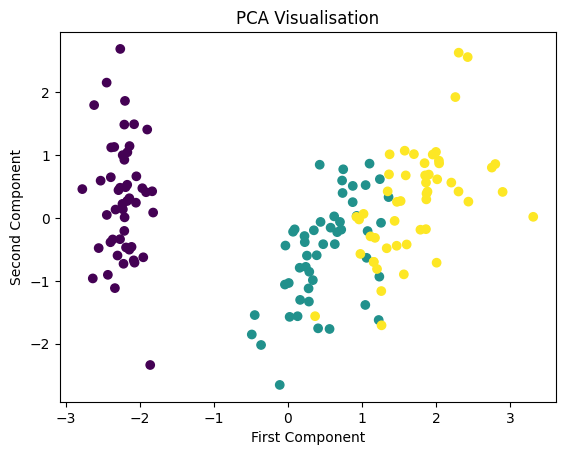

In [14]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plt.xlabel("First Component")
plt.ylabel("Second Component")
plt.title("PCA Visualisation")
plt.show()

In [15]:
print(pca.explained_variance_ratio_)
# PC1 ხსნის თავდაპირველი მონაცემების 73%-ს 
# PC2 ხსნის თავდაპირველი მონაცემების 23%-ს 

[0.72962445 0.22850762]


In [16]:
print(pca.components_)
# PC1 = 0.52106591 * F1 - 0.26934744 * F2 + 0.5804131 * F3 + 0.56485654 * F4
# PC2 = 0.37741762 * F1 + 0.92329566 * F2 + 0.02449161 * F3 + 0.06694199 * F4

[[ 0.52106591 -0.26934744  0.5804131   0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]]


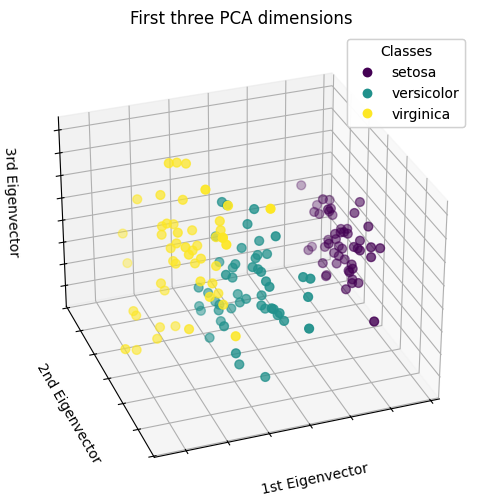

In [17]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(X_scaled)
scatter = ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=iris.target,
    s=40,
)

ax.set(
    title="First three PCA dimensions",
    xlabel="1st Eigenvector",
    ylabel="2nd Eigenvector",
    zlabel="3rd Eigenvector",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

legend1 = ax.legend(
    scatter.legend_elements()[0],
    iris.target_names.tolist(),
    loc="upper right",
    title="Classes",
)
ax.add_artist(legend1)

plt.show()

### Breast Cancer Wisconsin (Diagnostic) Data Set

In [18]:
# მონაცემების ჩატვირთვა
data = load_breast_cancer()
feature_names = data.feature_names
target_map = dict(enumerate(data.target_names))
X, y = pd.DataFrame(data.data, columns=feature_names), pd.Series(data.target).map(target_map)

df_cancer = X.copy()
df_cancer["diagnosis"] = y
df_cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [19]:
# მონაცემთა გაყოფა სასწავლო (80%) და სატესტო (20%) ნაწილებად
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
# მონაცემების სტანდარტიზაცია
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

In [21]:
# Principal Component Analysis (2 კომპონენტით)
pca = PCA(n_components=2)
pca.fit(X_scaled)

,n_components,2
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [22]:
# გარდავქმნათ მონაცემები: 30 Features -> 2 Features
X_pca = pca.transform(X_scaled)
X_scaled.shape, X_pca.shape

((455, 30), (455, 2))

In [23]:
# კომპონენტები
pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head()

,PC1,PC2
0,4.244903,9.131428
1,9.053755,0.475310
2,-2.275374,3.278471
3,-2.510453,0.743743
4,-2.302848,2.665155


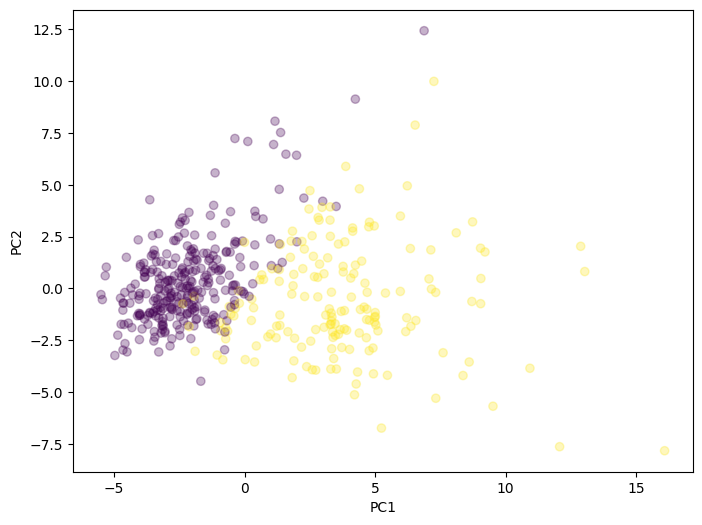

In [24]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y_train.astype("category").cat.codes, alpha=0.3)
plt.xlabel("PC1")
plt.ylabel("PC2");

In [25]:
# თითოეული კომპონენტისთვის თავდაპირველ მახასიათებლებითან დამოკიდებულება
# PC1 = a_1 * Feature_1 + a_2 * Feature_2 + ... + a_n * Feature_n 
df_comp = pd.DataFrame(pca.components_, columns=feature_names, index=["pc1", "pc2"])
df_comp

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
pc1,0.216015,0.101700,0.225181,0.218535,0.148982,0.240836,0.259500,0.263324,0.146217,0.065741,...,0.226392,0.105123,0.236126,0.224216,0.132348,0.211297,0.229556,0.252917,0.127241,0.132341
pc2,-0.240040,-0.051263,-0.222161,-0.236489,0.169316,0.150134,0.064037,-0.039640,0.183280,0.361447,...,-0.224548,-0.038994,-0.203586,-0.222669,0.156182,0.144035,0.102781,-0.005671,0.130100,0.277354


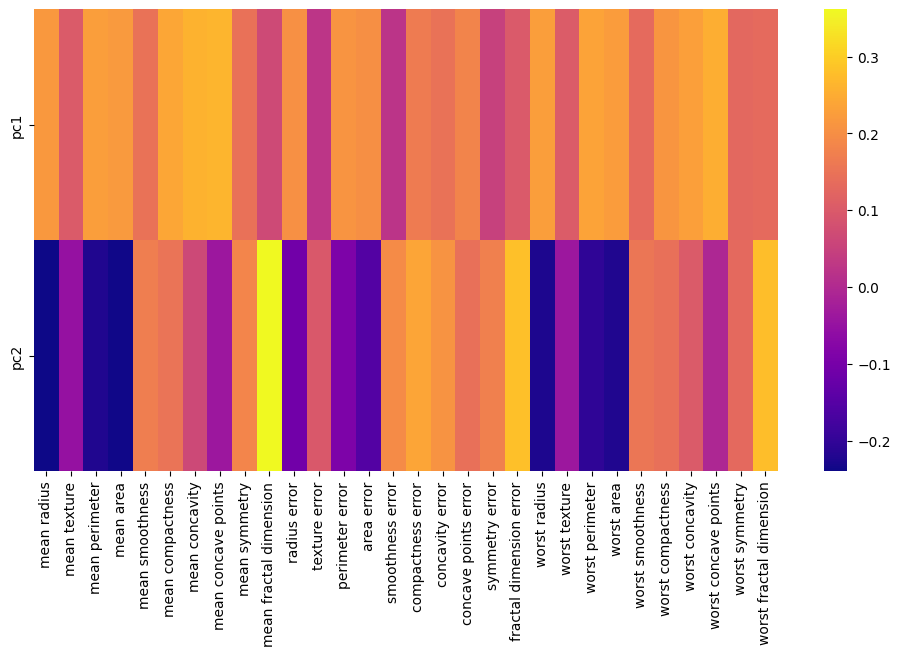

In [26]:
# თითოეული კომპონენტისთვის თავდაპირველ მახასიათებლებითან დამოკიდებულება
plt.figure(figsize=(12,6))
sns.heatmap(df_comp, cmap="plasma");

In [27]:
# გავწვრთნათ მოდელი
model = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, random_state=42)
model.fit(X_pca, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,500
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [28]:
# Feature Importance
pca_importances = model.feature_importances_

importance_df = pd.DataFrame({"Feature": ["PC1", "PC2"], "Importance": pca_importances})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
0,PC1,0.824305
1,PC2,0.175695


In [29]:
# რთულია ინტერპრეტაცია, გადავიყვანოთ ისევ თავდაპირველ სახეზე
# Backtransform to original feature space
pca_importances = model.feature_importances_ 
original_importances = np.dot(pca.components_.T, pca_importances)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": original_importances
}).sort_values(by="Importance", ascending=False)[:10]
importance_df

,Feature,Importance
6,mean concavity,0.225158
5,mean compactness,0.224900
7,mean concave points,0.210095
27,worst concave points,0.207484
26,worst concavity,0.207282
25,worst compactness,0.199479
15,compactness error,0.178438
17,concave points error,0.175511
16,concavity error,0.159383
22,worst perimeter,0.158871


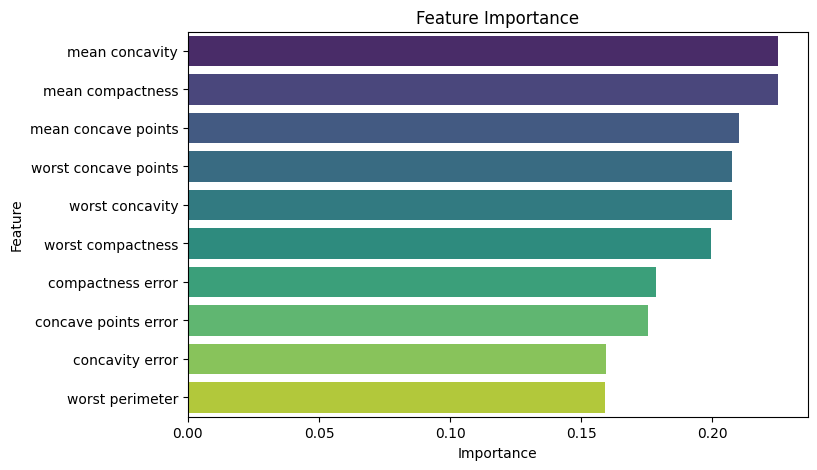

In [30]:
plt.figure(figsize=(8, 5))
sns.barplot(x=importance_df["Importance"], y=importance_df["Feature"], palette="viridis")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance");

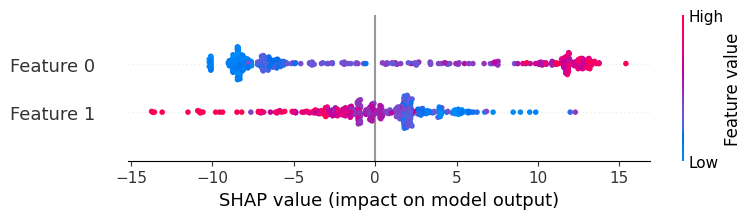

In [31]:
# SHAP Explainer (TreeExplainer უფრო სწრაფია decision tree-ზე)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_pca)

# SHAP Summary Plot – მახასიათებლების მნიშვნელობა და ზეგავლენა
shap.summary_plot(shap_values, X_pca)

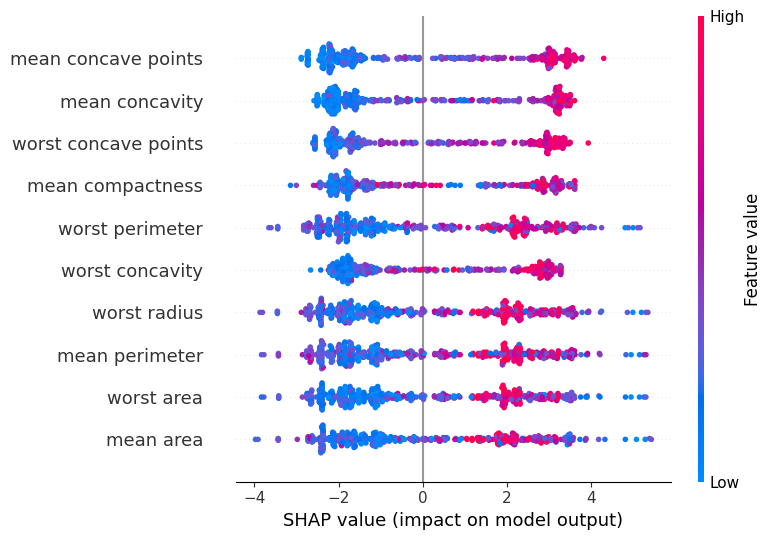

In [32]:
shap_values_original = np.dot(shap_values, pca.components_)
shap.summary_plot(
    shap_values_original, 
    features=X.iloc[X_train.index].values, 
    feature_names=feature_names, 
    max_display=10
)

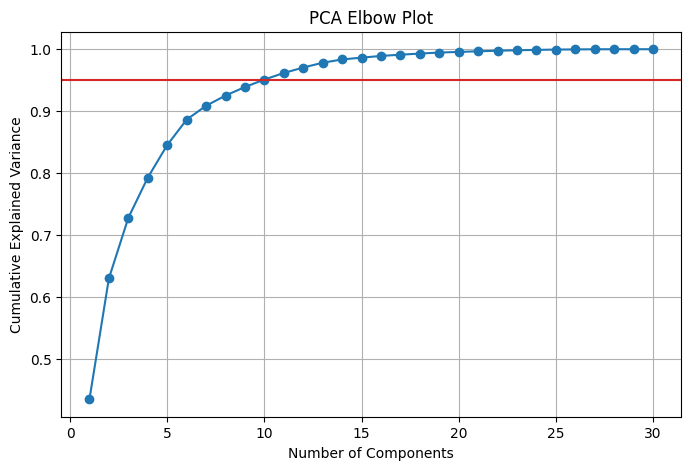

In [33]:
pca = PCA()
pca.fit(X_scaled)

# Calculate explained variance
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# elbow plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
plt.axhline(0.95, color="C3")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Elbow Plot")
plt.grid(True)
plt.show()

In [34]:
# პარამეტრის სახით გადავცეთ
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_scaled)
X_reduced.shape[1]

10

### გავწვრთნათ მოდელი 10 კომპონენტით

In [35]:
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=10)),
    ("gbc", GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, random_state=42))
])
pipe

,steps,"[('scale', ...), ('pca', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_components,10
,copy,True
,whiten,False
,svd_solver,'auto'


In [36]:
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

In [37]:
# შეფასება
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.97

Classification Report:
               precision    recall  f1-score   support

      benign       0.99      0.97      0.98        71
   malignant       0.95      0.98      0.97        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



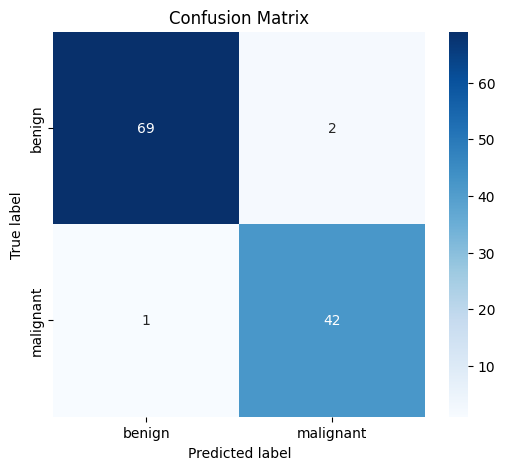

In [38]:
# confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["benign", "malignant"], yticklabels=["benign", "malignant"])
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

## UMAP (Uniform Manifold Approximation and Projection)

UMAP PCA-ს მსგავსად Dimensionality Reduction ალგორითმია. 

PCA (Principal Component Analysis) ეძებს თავდსაპირველი მახასიათებლების წრფივ კომბინაციას, ისე რომ რაც შეიძლება მეტი ვარიაცია ახსნან პირველმა კომპონენტებმა. 

როდესაც მონაცემებს არაწრფივი სტრუქტურა აქვთ (მაგალითად სპირალის ფორმის მონაცემები), ვარიაციის მაქსიმიზაცია ვერ გვეხმარება, PCA ვერ პოულობს სწორ სტრუქტურას.

UMAP PCA-გან განსხვავებით აგენერირებს მეზობლების გრაფს, ანუ ამოწმებს რომელი წერტილები არიან ერთმანეთთან ახლოს თავდაპირველ სივრცეში. შემდეგ ის ცდილობს, ამ დამოკიდებულებების გადმოტანას დაბალგანზომილებიან სივრცეში. ანუ ის ითვალისწინებს არა მხოლოდ გლობალურ განაწილებას, არამდე ლოკალურ დამოკიდებულებებს - რომელი მონაცემები არიან ერთმანეთის მსგავსი. თუ ორი წერტილი ძალიან გავს ერთმანეთს და ისინი ახლოს მდებარეობდნენ თავდაპირველ სივრცეში, ისინი დარჩებიან ახლოს UMAP ვიზუალიზაციაში. თუ ორი წერტილი განსხვავებულები არიან თავდაპირველ სივრცეში, ისინი გამოჩნდებიან ერთმანეთისაგან დაშორებით UMAP ვიზუალიზაციაში.

---
| მახასიათებელი                        | PCA           | UMAP                                     |
| ------------------------------------ | ------------- | ---------------------------------------- |
| ტიპი                   | წრფივი                                 | არაწრფივი                                             |
| არაწრფივი სტრუქტურები       | ვერ პოულობს        | მარტივად პოულობს                              |
| შენარჩუნებული სტრუქტურა| გლობალური                               | ლოკალური მეზობლობა                                     |
| ეფუძნება ვარიაციულობას              | ✓         | -                                    |
| ითვალისწინებს მსგავსებას             | -         | ✓ მეზობლობა ძალიან მნიშვნელოვანია |
| ტექნიკა            | ვარიაციის მაქსიმიზაცია                 | მეზობლების გეომეტრიული კავშირის შენარჩუნება            |
| კლასტერები              | ხშირად ერთმანეთზე გადადებული            | ცხადად გამოყოფილი კლასტერები     |
| აჩვენებს კლასტერებს რთულ მონაცემებზე | თითქმის ვერ | ძალიან კარგად გამოყოფს                 |
| სისწრაფე               | ძალიან სწრაფი                           | უფრო ნელია ვიდრე PCA                   |
| გამოყენება             | მონაცემთა წინასწარი დამუშავებისა და ანალიზისთვის | ვიზუალიზაცია, კლასტერების აღმოჩენა, მონაცემთა ინტუიციიური გაგება |

---

In [39]:
# სინთეტიკური მონაცემები
points = {
    "A": (1.72, 70),
    "B": (1.68, 68),
    "C": (1.74, 66),
    "D": (1.60, 55),
    "E": (1.63, 56),
    "F": (1.62, 54),
}
labels = list(points.keys())
X = np.array(list(points.values()))
colors = ["dodgerblue", "tomato", "hotpink", "gold", "gold", "gold"]

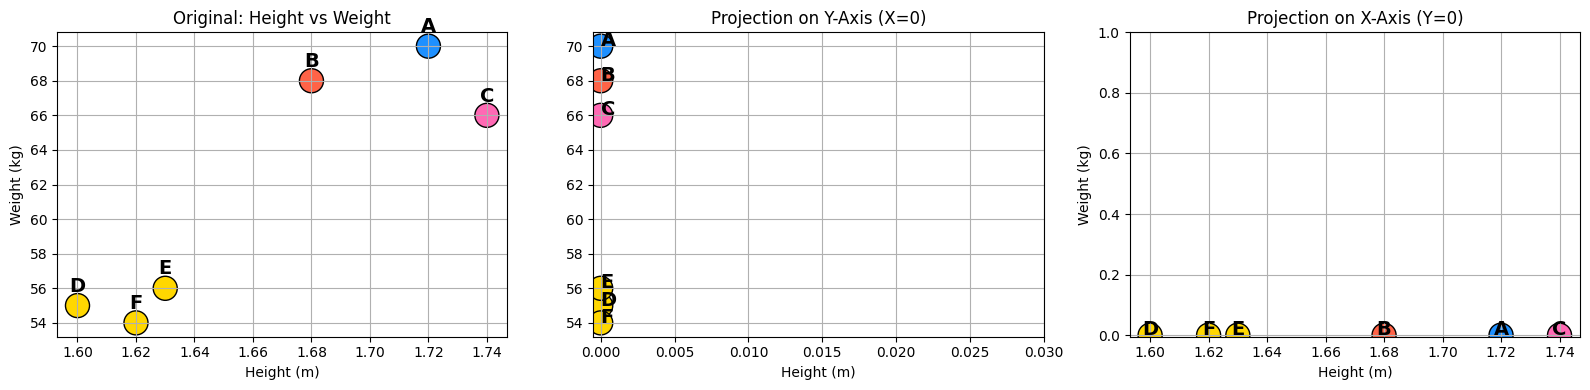

In [40]:
X_yproj = np.array([[0, y] for x, y in X])  # x = 0
X_xproj = np.array([[x, 0] for x, y in X])  # y = 0

fig, axs = plt.subplots(1, 3, figsize=(16, 4))

axs[0].scatter(X[:, 0], X[:, 1], c=colors, s=300, edgecolor="black")
for i, label in enumerate(labels):
    axs[0].text(X[i, 0], X[i, 1] + 0.8, label, ha="center", fontsize=14, fontweight="bold")
axs[0].set_title("Original: Height vs Weight")
axs[0].set_xlabel("Height (m)")
axs[0].set_ylabel("Weight (kg)")
axs[0].grid(True)

axs[1].scatter(X_yproj[:, 0], X_yproj[:, 1], c=colors, s=300, edgecolor="black")
for i, label in enumerate(labels):
    axs[1].text(X_yproj[i, 0], X_yproj[i, 1], label, ha="left", fontsize=14, fontweight="bold")
axs[1].set_title("Projection on Y-Axis (X=0)")
axs[1].set_xlabel("Height (m)")
axs[1].set_xlim(-0.0005, 0.03)
axs[1].grid(True)

axs[2].scatter(X_xproj[:, 0], X_xproj[:, 1], c=colors, s=300, edgecolor="black")
for i, label in enumerate(labels):
    axs[2].text(X_xproj[i, 0], X_xproj[i, 1] + 0.002, label, ha="center", fontsize=14, fontweight="bold")
axs[2].set_title("Projection on X-Axis (Y=0)")
axs[2].set_xlabel("Height (m)")
axs[2].set_ylabel("Weight (kg)")
axs[2].set_ylim(-0.005, 1)
axs[2].grid(True)

plt.tight_layout()
plt.show()

UMAP პირველ ეტაპზე ქმნის გრაფს. წყვილებს შორის წონა დამოკიდებულია მათ შორის მანძილზე — რაც უფრო ახლოსაა წერტილები, მით უფრო მაღალია წონა.

გამოიყენება n_neighbors – ანუ თითოეულ წერტილს აქვს ლოკალური მეზობლების ჯგუფი. ამას ეწოდება fuzzy topological graph – ანუ ბუნდოვანი ტოპოლოგიური გრაფი მაღალგანზომილებიან სივრცეში.

შემდეგ UMAP ცდილობს „გადმოიტანოს“ ეს გრაფი, ანუ მეზობლობათა ურთიერთობები, ახალ სივრცეში (მაგალითად, 2D ან 1D), ასე რომ მეზობლები ახლოს დარჩნენ, ხოლო შორები შორს.

ამისთვის ითვლება მეორე გრაფიც დაბალგანზომილებიან სივრცეში, და შემდეგ ცდილობს ამ ორ გრაფს შორის სხვაობა შეამციროს.

---

UMAP – 5 ძირითადი ნაბიჯი

1. K-მეზობლების პოვნა:
   ყოველი წერტილისთვის ვპოულობთ `n_neighbors` რაოდენობის უახლოეს მეზობელს მაღალგანზომილებიან სივრცეში.

2. ბუნდოვანი (Fuzzy) გრაფის აგება:
   ვქმნით წონიან გრაფს, სადაც ერთმანეთთან ახლოს მყოფ წყვილებს მაღალი კავშირი აქვთ.

3. დაბალგანზომილებიანი გრაფის ინიციალიზაცია:
   ვაწყობთ წერტილებს შემთხვევით 2D ან 1D სივრცეში და ვქმნით მეორე გრაფს ახალ სივრცეში.

4. ოპტიმიზაცია (Cross-Entropy მინიმიზაცია):
   ვამუშავებთ მოდელს ისე, რომ ახალ სივრცეში მეზობლები დარჩნენ ახლოს

5. შედეგის გამოყენება, ვიზუალიზაცია:
   მიღებული მონაცემები შეიძლება გამოვიყენოთ გრაფიკზე გამოსატანად ან სხვა მოდელების გასაწვრთნელად

In [41]:
# nearest neighbors
nn = NearestNeighbors(n_neighbors=3)
nn.fit(X)
neighbors = nn.kneighbors(X, return_distance=False)

neighbors # გვაძლევს თითოეული მონაცემის წერტილისთვის მისი უახლოესი მეზობლების ინდექსებს

array([[0, 1, 2],
       [1, 0, 2],
       [2, 1, 0],
       [3, 5, 4],
       [4, 3, 5],
       [5, 3, 4]])

UMAP-ის ძირითადი პარამეტრები:

* `n_neighbors` – განსაზღვრავს მეზობლების რაოდენობას, რომელიც გავლენას ახდენს ლოკალურ/გლობალურ სტრუქტურაზე.
* `min_dist` – განსაზღვრავს რამდენად შეიძლება იყვნენ წერტილები ახლოს ერთმანეთთან (კლასტერის სიმჭიდროვე).
* `metric` – მანძილის ტიპი (მაგ: `'euclidean'`, `'cosine'` და სხვა).

In [42]:
# Apply UMAP dimensionality reduction (2D → 1D)
reducer = umap.UMAP(n_neighbors=3, n_components=1, random_state=42) # n_components=1 → ერთ განზომილებაში გადაყვანა (1D)
X_umap = reducer.fit_transform(X)

In [43]:
umap_1d_map = dict(zip(points.keys(), X_umap[:, 0])) 

for city, value in umap_1d_map.items():
    print(f"{city}: {value:.4f}")

A: 5.7554
B: 5.1480
C: 6.2343
D: -10.0641
E: -9.4257
F: -10.6037


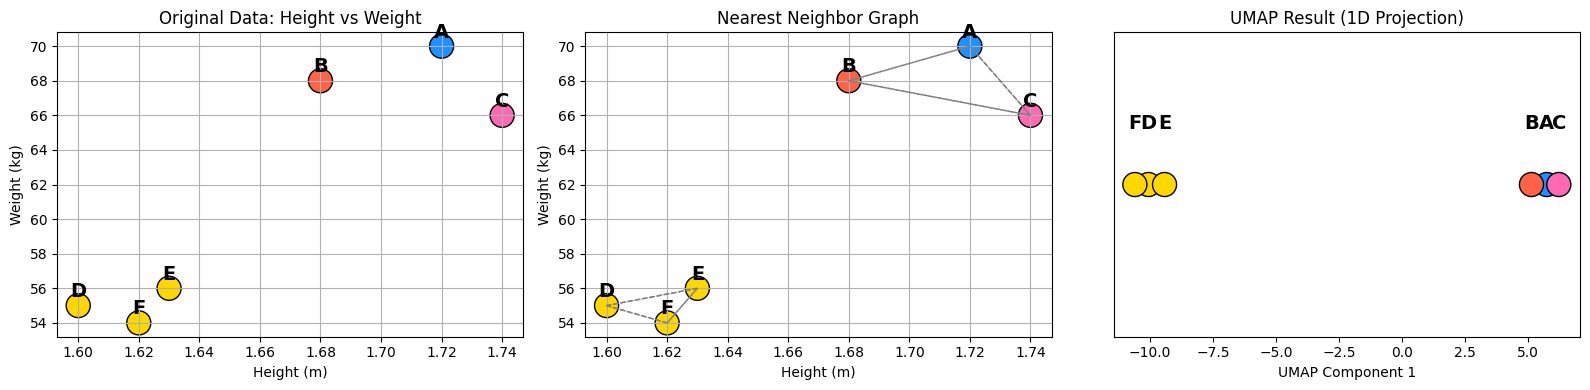

In [44]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

axs[0].scatter(X[:, 0], X[:, 1], c=colors, s=300, edgecolor="black")
for i, label in enumerate(labels):
    axs[0].text(X[i, 0], X[i, 1] + 0.5, label, ha="center", fontsize=14, fontweight="bold")
axs[0].set_title("Original Data: Height vs Weight")
axs[0].set_xlabel("Height (m)")
axs[0].set_ylabel("Weight (kg)")
axs[0].grid(True)

axs[1].scatter(X[:, 0], X[:, 1], c=colors, s=300, edgecolor="black")
for i in range(len(X)):
    for j in neighbors[i]:
        if i != j:
            axs[1].plot([X[i, 0], X[j, 0]], [X[i, 1], X[j, 1]], "gray", linestyle="--", linewidth=1)
for i, label in enumerate(labels):
    axs[1].text(X[i, 0], X[i, 1] + 0.5, label, ha="center", fontsize=14, fontweight="bold")
axs[1].set_title("Nearest Neighbor Graph")
axs[1].set_xlabel("Height (m)")
axs[1].set_ylabel("Weight (kg)")
axs[1].grid(True)

axs[2].scatter(X_umap[:, 0], [0]*len(X), c=colors, s=300, edgecolor="black")
for i, label in enumerate(labels):
    axs[2].text(X_umap[i, 0], 0.02, label, ha="center", fontsize=14, fontweight="bold")
axs[2].set_title("UMAP Result (1D Projection)")
axs[2].set_yticks([])
axs[2].set_xlabel("UMAP Component 1")

plt.tight_layout()
plt.show()

### make_moons

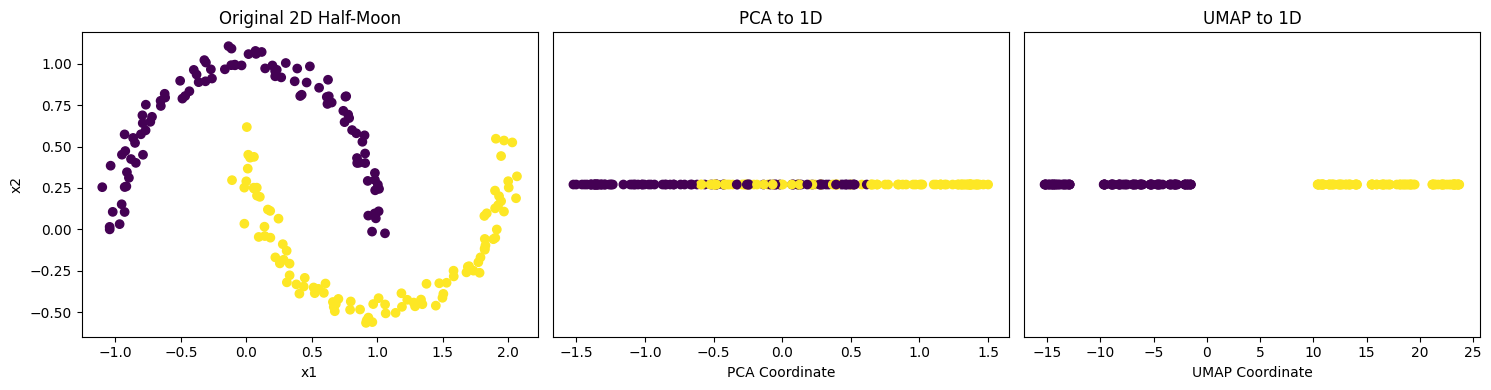

In [45]:
# სინთეტიკური მონაცემები
X, y = make_moons(n_samples=200, noise=0.05, random_state=42)

X_pca = PCA(n_components=1).fit_transform(X)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.01, n_components=1, random_state=42)
X_umap = reducer.fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(X[:, 0], X[:, 1], c=y)
axes[0].set_title("Original 2D Half-Moon")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")

axes[1].scatter(X_pca, [0]*len(X_pca), c=y)
axes[1].set_title("PCA to 1D")
axes[1].set_xlabel("PCA Coordinate")
axes[1].set_yticks([])

axes[2].scatter(X_umap, [0]*len(X_umap), c=y)
axes[2].set_title("UMAP to 1D")
axes[2].set_xlabel("UMAP Coordinate")
axes[2].set_yticks([])

plt.tight_layout()
plt.show()

### Digits dataset - a small version of MNIST: ხელნაწერი ციფრები (0-9), (data - 8x8 პიქსელების grayscale სურათები)

In [46]:
digits = load_digits()
X, y = digits.data, digits.target

In [47]:
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X)

In [48]:
df_umap = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])

In [49]:
fig = px.scatter(
    df_umap, x="UMAP1", y="UMAP2", color=y.astype(str), labels={"color": "digit"}
)
fig.show()

In [50]:
# k-means-Clustering with k=10 
km = KMeans(n_clusters=10, max_iter=100, n_init=1, random_state=1, tol=0)
cluster_labels = km.fit_predict(X_umap)

In [51]:
df_cluster_table = pd.crosstab(y, cluster_labels)
df_cluster_table.columns = [f"Cluster {i}" for i in df_cluster_table.columns]
df_cluster_table

,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8,Cluster 9
row_0,,,,,,,,,,
0,0,178,0,0,0,0,0,0,0,0
1,0,0,27,0,0,0,0,44,0,111
2,0,0,0,0,166,0,1,10,0,0
3,173,0,0,0,0,1,1,8,0,0
4,0,0,0,176,0,0,4,0,0,1
5,0,0,1,0,0,179,0,0,2,0
6,0,0,180,0,0,0,0,1,0,0
7,0,0,0,0,0,0,179,0,0,0
8,2,0,0,0,0,0,0,167,0,5


In [52]:
fig = px.scatter(
    df_umap, x="UMAP1", y="UMAP2", 
    color=cluster_labels.astype(str), labels={"color": "digit"}
)
fig.show()

### Mice Protein Expression dataset
მონაცემთა ნაკრები შეიცავს 77 თაგვის სხვადასხვა ცილების დონეებს. თითოეული თაგვი წარმოდგენილია 77 ცილოვანი მახასიათებლით.
    
| მახასიათებელი        | მნიშვნელობა                                                                               |
| -------------------- | ----------------------------------------------------------------------------------------- |
| `Genotype`           | გენოტიპი (Control / Ts65Dn)                                                               |
| `Treatment`          | მკურნალობა (Saline / Memantine)                                                           |
| `Behavior`           | ქცევითი მდგომარეობა (C/S)                                                                 |
| `DYRK1A`, `pS6`, ... | ცილების ექსპრესიის დონეები                           |
| `class`              | Target Label  |

In [53]:
# მონაცემების ჩატვირთვა
mice_protein_expression = fetch_ucirepo(id=342) 
X = mice_protein_expression.data.features 
y = mice_protein_expression.data.targets 
X = X.iloc[:, :77].dropna()
y = y.iloc[X.index]
X.head()

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
75,0.649781,0.828696,0.405862,2.921435,5.167979,0.207174,0.176640,3.728084,0.239283,1.666579,...,0.239752,0.139052,0.112926,0.132001,0.129363,0.486912,0.125152,0.146865,0.143517,1.627181
76,0.616481,0.841974,0.388584,2.862575,5.194163,0.223433,0.167725,3.648240,0.221030,1.565150,...,0.249031,0.133787,0.121607,0.139008,0.143084,0.467833,0.112857,0.161132,0.145719,1.562096
77,0.637424,0.852882,0.400561,2.968155,5.350820,0.208790,0.173261,3.814545,0.222300,1.741732,...,0.247956,0.142324,0.130261,0.134804,0.147673,0.462501,0.116433,0.160594,0.142879,1.571868
78,0.576815,0.755390,0.348346,2.624901,4.727509,0.205892,0.161192,3.778530,0.194153,1.505475,...,0.233225,0.133637,0.107321,0.118982,0.121290,0.479110,0.102831,0.144238,0.141681,1.646608
79,0.542545,0.757917,0.350051,2.634509,4.735602,0.210526,0.165671,3.871971,0.194297,1.531613,...,0.244469,0.133358,0.112851,0.128635,0.142617,0.438354,0.110614,0.155667,0.146408,1.607631


In [54]:
# UMAP 
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
X_umap = reducer.fit_transform(X)

In [55]:
labels = y["class"].astype(str)

df_plot = pd.DataFrame({
    "UMAP1": X_umap[:, 0],
    "UMAP2": X_umap[:, 1],
    "Genotype": labels
})

# Interaktiver Scatter-Plot
fig = px.scatter(
    df_plot,
    x="UMAP1",
    y="UMAP2",
    color="Genotype",
    title="Mice Protein Expression - UMAP (colored by Genotype)",
    hover_data=["Genotype"],
    width=900,
    height=600
)

fig.show()